# 03 · Baseline (B0, reference model)

Hashed word n-gram TF-IDF + classical linear models. The grid is searched on a train subsample (`search_docs`) and scored on the validation split; the best configuration is refit on the full train part. B0 is frozen here and is the reference for every experiment.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

from hw3.config import ROOT, art, load_config

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)
FIG = ROOT / "images"

from hw3.runs import report
from hw3.tfidf import run_baseline

cfg = load_config("baseline")
cfg

{'id': 'B0',
 'reference': None,
 'change': 'reference model: global word TF-IDF (hashing) + classical linear models, small grid search',
 'notes': 'frozen before any experiment; every experiment is compared against it',
 'seed': 42,
 'search_docs': 40000,
 'fit_docs': None,
 'features': {'word11': {'analyzer': 'word',
   'ngram_range': [1, 1],
   'lowercase': True},
  'word12': {'analyzer': 'word', 'ngram_range': [1, 2], 'lowercase': True}},
 'grid': {'features': [['word11'], ['word12']],
  'models': [{'name': 'linear_svc', 'C': 0.1, 'class_weight': 'balanced'},
   {'name': 'linear_svc', 'C': 0.3, 'class_weight': 'balanced'},
   {'name': 'linear_svc', 'C': 1.0, 'class_weight': 'balanced'},
   {'name': 'linear_svc', 'C': 3.0, 'class_weight': 'balanced'},
   {'name': 'complement_nb', 'alpha': 0.1},
   {'name': 'complement_nb', 'alpha': 1.0}]}}

In [2]:
grid = run_baseline(cfg)
grid[["features", "model", "macro_f1", "f1_human", "f1_ai", "f1_fusion"]]

,features,model,macro_f1,f1_human,f1_ai,f1_fusion
0,[word12],"{'name': 'linear_svc', 'C': 3.0, 'class_weight...",0.836124,0.773274,0.974254,0.760845
1,[word12],"{'name': 'linear_svc', 'C': 1.0, 'class_weight...",0.835516,0.776154,0.973352,0.757042
2,[word12],"{'name': 'linear_svc', 'C': 0.3, 'class_weight...",0.827144,0.772243,0.971261,0.737928
3,[word11],"{'name': 'linear_svc', 'C': 0.3, 'class_weight...",0.821643,0.753567,0.971044,0.740318
4,[word11],"{'name': 'linear_svc', 'C': 1.0, 'class_weight...",0.817909,0.740210,0.970371,0.743147
5,[word11],"{'name': 'linear_svc', 'C': 0.1, 'class_weight...",0.816227,0.758159,0.967804,0.722717
6,[word12],"{'name': 'linear_svc', 'C': 0.1, 'class_weight...",0.809455,0.761595,0.964519,0.702252
7,[word11],"{'name': 'linear_svc', 'C': 3.0, 'class_weight...",0.809059,0.724171,0.967609,0.735397
8,[word12],"{'name': 'complement_nb', 'alpha': 0.1}",0.683192,0.651483,0.905388,0.492704
9,[word11],"{'name': 'complement_nb', 'alpha': 0.1}",0.563703,0.506744,0.791317,0.393046


,precision,recall,f1,support
human,0.7559,0.8799,0.8132,6672
ai,0.9708,0.9852,0.9779,12196
fusion,0.8783,0.7444,0.8058,8366


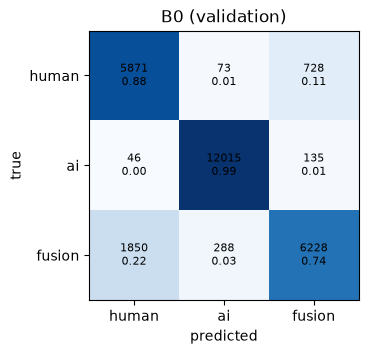

In [3]:
rep = report("B0")
rep["figure"].savefig(FIG / "confusion_B0.png", dpi=150, bbox_inches="tight")
rep["per_class"]

In [4]:
rep["by_domain"]

n  macro_f1
de-DE bundestag               5235    0.9072
      gutenberg                 39    0.4953
en-EN arxiv_papers            1429    0.8494
      blog_authorship_corpus  4055    0.7376
      cnn_news                4429    0.8272
      euro_court_cases        2758    0.8991
      gutenberg                692    0.7373
      house_of_commons        3186    0.8725
      student_essays          5411    0.9097